# Setup

In [1]:
from pprint import pprint
from pathlib import Path
from dotenv import dotenv_values


# Config
cfg = dotenv_values()
pprint(cfg)


# Suppress warnings
import warnings
from bs4 import GuessedAtParserWarning

warnings.filterwarnings("ignore", category=GuessedAtParserWarning)

OrderedDict({'CHAT_SMALL': 'qwen3:0.6b', 'SEED': '42'})


In [2]:
from typing import TypedDict
from pydantic import BaseModel
from IPython.display import Image

from langchain_ollama import ChatOllama
from langchain.messages import SystemMessage, HumanMessage, ToolMessage
from langchain.tools import tool, ToolRuntime, ToolException
from langchain.agents.middleware import ToolCallLimitMiddleware
from langchain.agents import AgentState, create_agent

from langgraph.types import Command

# 1. Chat

## 1.1. Chat Model

In [3]:
chat = ChatOllama(
    model=cfg['CHAT_SMALL'],
    reasoning=True,
    seed=cfg['SEED'],
)

## 1.2. System Prompt

In [4]:
system_prompt = SystemMessage(
    "You are a helpful assitant."
)

## 1.3. Response Format

In [5]:
class AnswerWithReason(BaseModel):
    """Response the answer with reason."""
    answer: str
    reason: str

# 2. Context

## 2.1. Agent State

In [6]:
class SimpleAgentState(AgentState):
    """Simple agent state."""
    last_sum: int

## 2.2. Runtime Context

In [7]:
class AgentContext(TypedDict):
    """Runtime context."""
    user_id: str

## 2.3. Run Config

In [8]:
config = {
    'configurable': {
        'thread_id': 'test-1',
    }
}

# 3. Tool

In [9]:
@tool
def add_ints(
    x: int, y: int,
    runtime: ToolRuntime[AgentContext],
) -> Command:
    """Add two integers and return updated state."""
    user_id = runtime.context['user_id']

    # Exception handling
    if x < 0 or y < 0:
        raise ToolException("Negative integers are not allowed.")

    result = x + y

    return Command(
        update={
            'last_sum': result,
            'messages': [
                ToolMessage(str(result), tool_call_id=runtime.tool_call_id),
            ]
        }
    )


# Allow the agent to handle ToolException
add_ints.handle_tool_error = True

# 4. Middleware

- https://docs.langchain.com/oss/python/langchain/middleware/built-in

| Index | Name | Description |
|---:|---|---|
| 1 | `ToolErrorMiddleware` | Catch tool execution exceptions and convert them to error messages for the model. |
| 2 | `ToolRetryMiddleware` | Automatically retry temporary-failed tool calls with exponential backoff. |
| 3 | `ModelRetryMiddleware` | Automatically retry failed model calls with exponential backoff. |
| 4 | `ModelFallbackMiddleware` | Automatically fallback to alternative models when primary fails. |
| 5 | `SummarizationMiddleware` | Automatically summarize conversation history when approaching token limits. |
| 6 | `HumanInTheLoopMiddleware` | Pause execution for human approval of tool calls. |
| 7 | `ModelCallLimitMiddleware` | Limit the number of model calls to prevent excessive costs. |
| 8 | `ToolCallLimitMiddleware` | Control tool execution by limiting call counts. |
| 9 | `PIIMiddleware` | Detect and handle Personally Identifiable Information (PII). |
| 10 | `TodoListMiddleware` | Equip agents with task planning and tracking capabilities. |
| 11 | `LLMToolSelectorMiddleware` | Use an LLM to select relevant tools before calling main model. |
| 12 | `ProviderToolSearchMiddleware` | Defer tools behind providers' server-side tool search, surfacing them on demand. |
| 13 | `ShellToolMiddleware` | Expose a persistent shell session to agents for command execution. |
| 14 | `FilesystemMiddleware` | Provide agents with a filesystem for storing context and long-term memories. |
| 15 | `SubAgentMiddleware` | Add the ability to spawn subagents. |
| 16 | `RubricMiddleware` | Apply LLM-as-a-judge grading so agents self-evaluate and iterate until a rubric is satisfied. **(beta)** |
| 17 | `FilesystemFileSearchMiddleware` | Provide Glob and Grep search tools over filesystem files. |
| 18 | `ContextEditingMiddleware` | Manage conversation context by trimming or clearing tool uses. |
| 19 | `LLMToolEmulator` | Emulate tool execution using an LLM for testing purposes. |

## 4.1. Call Control

| Index | Name | Description |
|---:|---|---|
| 1 | `ToolErrorMiddleware` | Catch tool execution exceptions and convert them to error messages for the model. |
| 2 | `ToolRetryMiddleware` | Automatically retry temporary-failed tool calls with exponential backoff. |
| 3 | `ModelRetryMiddleware` | Automatically retry failed model calls with exponential backoff. |
| 4 | `ModelFallbackMiddleware` | Automatically fallback to alternative models when primary fails. |
| 5 | `ToolCallLimitMiddleware` | Control tool execution by limiting call counts. |
| 6 | `ModelCallLimitMiddleware` | Limit the number of model calls to prevent excessive costs. |

### 4.1.1. ToolErrorMiddleware

In [10]:
from langchain.agents.middleware import ToolErrorMiddleware, ToolCallRequest


# Chat
chat  = ChatOllama(
    model=cfg['CHAT_SMALL'],
    reasoning=True,
    seed=cfg['SEED'],
)

# Tool
@tool
def add_ints(x: int, y: int) -> int:
    """Return x + y"""
    if x < 0:
        raise ValueError("x must be > 0!")
    return x + y

@tool
def divide_by_int(x: int, y: int) -> int:
    """Return x / y"""
    return x / y

# Middleware
def on_error(exception: Exception, request: ToolCallRequest) -> str | None:
    match exception:
        case ZeroDivisionError():
            return f"Tool: {request.tool_call['name']}, Error: {str(ValueError.__name__)}, Fix: y can not be zero!"
        case _:
            return f"Tool: {request.tool_call['name']}, Error: {type(exception).__name__}"

tool_error_middleware = ToolErrorMiddleware(
    on_error=on_error,
    tools=[divide_by_int],
)

# Agent
agent = create_agent(
    model=chat,
    tools=[add_ints, divide_by_int],
    middleware=[
        ToolErrorMiddleware(
            on_error=on_error,
            tools=[divide_by_int],
        )
    ],
)

# Response
response = agent.invoke(
    input={
        'messages': [
            SystemMessage("You must call at least one tool."),
            HumanMessage("Call the tool named 'divide_by_int' with (x=5, y=0)."),
        ],
    }
)

for message in response['messages']:
    print(message.pretty_repr(), '\n')

================================ System Message ================================

You must call at least one tool. 

================================ Human Message =================================

Call the tool named 'divide_by_int' with (x=5, y=0). 

================================== Ai Message ==================================
Tool Calls:
  divide_by_int (c9f0e65d-9246-44dd-a1e5-3630b6a52eab)
 Call ID: c9f0e65d-9246-44dd-a1e5-3630b6a52eab
  Args:
    x: 5
    y: 0 

================================= Tool Message =================================
Name: divide_by_int

Tool: divide_by_int, Error: ValueError, Fix: y can not be zero! 

================================== Ai Message ==================================

The function `divide_by_int` cannot be used with `y=0` because division by zero is undefined. To proceed, I'll use the `add_ints` tool to calculate the sum of `x=5` and `y=0`. 

**Result:**
Tool Calls:
  add_ints (bf952e88-6b41-4e73-aae8-2cfc393c2d44)
 Call ID: bf952e88-6b

### 4.1.2. ToolRetryMiddleware

In [11]:
from typing import List
from langchain.agents.middleware import ToolRetryMiddleware
import wikipediaapi
from langchain.tools import tool


# Tool - Wiki
wiki = wikipediaapi.Wikipedia(
    user_agent='LangChainRAG/1.0',
    language='en',
)

@tool
def search_tool(keyword: str) -> List[str]:
    """Search Wikipedia and return relevant article summaries."""
    pages = wiki.search(keyword, limit=3).pages

    results = []
    for keyword, value in pages.items():
        results.append(f"[{keyword}]\n{value.text[:100]} ...\n")

    return results

# Agent
agent = create_agent(
    model=chat,
    tools=[search_tool],
    middleware=[
        ToolRetryMiddleware(
            initial_delay=0.1,      # if fail, wait 0.1 secs and retry.
            backoff_factor=2.0,     # if fail again, wait x2.0 times and retry again.
            max_retries=2,          # retry 2 more times: 0.1 -> 0.2 -> 0.4 secs.
        ),
    ],
)

# Response
response = agent.invoke(
    input={
        'messages': [
            SystemMessage("You must use the provided tool to search on Wikipedia. Example usage: search_tool('RAG')"),
            HumanMessage("What is Agent AI?"),
        ],
    }
)

for message in response['messages']:
    print(message.pretty_repr(), '\n')

================================ System Message ================================

You must use the provided tool to search on Wikipedia. Example usage: search_tool('RAG') 

================================ Human Message =================================

What is Agent AI? 

================================== Ai Message ==================================
Tool Calls:
  search_tool (bf034b06-fc62-454a-8bc1-39a1b08cad8a)
 Call ID: bf034b06-fc62-454a-8bc1-39a1b08cad8a
  Args:
    keyword: Agent AI 

================================= Tool Message =================================
Name: search_tool

["[AI agent]\nAn AI agent, also known as agentic AI, is an artificial intelligence program that can make decisions ...\n", "[OpenAI rogue agent breach of Hugging Face]\nIn July 2026, AI agents developed by OpenAI escaped their testing sandbox to access the Internet and ...\n", "[Muse (AI agent)]\nMuse is an artificial intelligence agent developed by Meta Platforms, announced on  September 8, 202 .

### 4.1.3. ModelRetryMiddleware

In [12]:
from langchain.agents.middleware import ModelRetryMiddleware


agent = create_agent(
    model=chat,
    tools=[search_tool],
    middleware=[
        ModelRetryMiddleware(
            initial_delay=0.1,      # if fail, wait 0.1 secs and retry.
            backoff_factor=2.0,     # if fail again, wait x2.0 times and retry again.
            max_retries=2,          # retry 2 more times: 0.1 -> 0.2 -> 0.4 secs.
        ),
    ],
)

### 4.1.4. ModelFallbackMiddleware

In [13]:
from langchain.agents.middleware import ModelFallbackMiddleware


agent = create_agent(
    model=chat,
    tools=[search_tool],
    middleware=[
        ModelFallbackMiddleware(
            ChatOllama(model='qwen3:0.6b'),   # 1st fallback
            ChatOllama(model='qwen3:1.7b'),   # 2nd fallback
            ChatOllama(model='qwen3:4b'),     # 3rd fallback, ...
        ),
    ],
)

### 4.1.5. ToolCallLimitMiddleware

In [14]:
from langchain.agents.middleware import ToolCallLimitMiddleware


agent = create_agent(
    model=chat,
    tools=[search_tool],
    middleware=[
        ToolCallLimitMiddleware(
            tool_name='search_tool',
            thread_limit=5,             # per one thread (= conversation)
            run_limit=3,                # per single run, i.e. request -> response
            exit_behavior='continue',   # block exceeded tool with error messages and continue (default)
        ),
        ToolCallLimitMiddleware(        # one middleware for each tool
            tool_name='some_tool',      # does not raise error
            thread_limit=10,
            run_limit=5,
            exit_behavior='error',      # stop immediately with `ToolCallLimitExceededError`
        ),
    ],
)

### 4.1.6. ModelCallLimitMiddleware

In [15]:
from langchain.agents.middleware import ModelCallLimitMiddleware


agent = create_agent(
    model=chat,
    tools=[search_tool],
    middleware=[
        ModelCallLimitMiddleware(
            thread_limit=5,             # per one thread (= conversation)
            run_limit=3,                # per single run, i.e. request -> response
            exit_behavior='end',        # 'end': graceful termination (default), 'error': raise exception
        ),
    ],
)

## 4.2. Tool Search

| Index | Name | Description |
|---:|---|---|
| 1 | `LLMToolSelectorMiddleware` | Use an LLM to select relevant tools before calling main model. |
| 2 | `HumanInTheLoopMiddleware` | Pause execution for human approval of tool calls. |
| 3 | `LLMToolEmulator` | Emulate tool execution using an LLM for testing purposes. |
| 4 | `ProviderToolSearchMiddleware` | Defer tools behind providers' server-side tool search, surfacing them on demand. |

### 4.2.1. LLMToolSelectorMiddleware

In [16]:
from langchain.agents.middleware import LLMToolSelectorMiddleware


tool_selector = ChatOllama(
    model=cfg['CHAT_SMALL'],
)
tool_selector_prompt = "You are a subagent for tool selection."

agent = create_agent(
    model=chat,
    tools=[search_tool],
    middleware=[
        LLMToolSelectorMiddleware(
            model=tool_selector,                    # tool selector
            system_prompt=tool_selector_prompt,     # tool selection prompt
            max_tools=3,                            # choose up to 3 tools
            always_include=['search_tool'],         # not included in max_tools
        ),
    ],
)

### 4.2.2. HumanInTheLoopMiddleware

In [17]:
from langchain.agents.middleware import HumanInTheLoopMiddleware
from langgraph.checkpoint.memory import InMemorySaver


# Tool
@tool
def add_ints(x: int, y: int) -> int:
    """Return x + y"""
    if x < 0:
        raise ValueError("x must be > 0!")
    return x + y

@tool
def divide_by_int(x: int, y: int) -> int:
    """Return x / y"""
    return x / y

# Agent
agent = create_agent(
    model=chat,
    tools=[add_ints, divide_by_int],
    checkpointer=InMemorySaver(),       # HITL requires checkpointer
    middleware=[
        HumanInTheLoopMiddleware(
            interrupt_on={
                'add_ints': False,      # execute immediately
                'divide_by_int': {
                    'allowed_decisions': ['approve', 'edit', 'reject'],
                    'description': "Wait for user approval.",
                    'when': lambda request: request.tool_call['args']['y'] == 0,
                },
            }
        ),
    ],
)

# Initial invocation
config = {
    'configurable': {
        'thread_id': 'test-1',
    }
}

response = agent.invoke(
    input={
        'messages': [
            HumanMessage("Call divide_by_int(x=4, y=2)."),
        ],
    },
    config=config,
)

# Approve
if '__interrupt__' in response.keys():
    pprint(response['__interrupt__'][0].value, sort_dicts=False)
    args_y = response['__interrupt__'][0].value['action_requests'][0]['args']['y']
    approval = 'reject' if args_y == 0 else 'accept'
else:
    approval = None

# Resume
response = agent.invoke(
    Command(resume={
        'decisions': [{'type': approval}],
    }),
    config=config,
)

for message in response['messages']:
    print(message.pretty_repr(), '\n')

================================ Human Message =================================

Call divide_by_int(x=4, y=2). 

================================== Ai Message ==================================
Tool Calls:
  divide_by_int (43ebc6cc-6b09-41db-9c77-3f79fe8286dc)
 Call ID: 43ebc6cc-6b09-41db-9c77-3f79fe8286dc
  Args:
    x: 4
    y: 2 

================================= Tool Message =================================
Name: divide_by_int

2.0 

================================== Ai Message ==================================

The result of dividing 4 by 2 is 2.0. 



### 4.2.3. LLMToolEmulator

In [18]:
from langchain.agents.middleware import LLMToolEmulator


# Agent
agent = create_agent(
    model=chat,
    tools=[add_ints, divide_by_int],
    middleware=[
        LLMToolEmulator(
            model=ChatOllama(model=cfg['CHAT_SMALL']),
            tools=[divide_by_int],      # it may or may not be actually run!
        ),
    ],
)

# Response
response = agent.invoke({
    "messages": [
        HumanMessage("What is divide_by_int(x=2, y=0)?"),
    ],
})

for message in response['messages']:
    print(message.pretty_repr(), '\n')

================================ Human Message =================================

What is divide_by_int(x=2, y=0)? 

================================== Ai Message ==================================
Tool Calls:
  divide_by_int (6e41ff9f-a01b-4767-91a2-473918952f49)
 Call ID: 6e41ff9f-a01b-4767-91a2-473918952f49
  Args:
    x: 2
    y: 0 

================================= Tool Message =================================
Name: divide_by_int

2 / 0 

================================== Ai Message ==================================

The result of dividing 2 by 0 is undefined (division by zero). 



### 4.2.4. ProviderToolSearchMiddleware

In [19]:
import os
from langchain_openai import ChatOpenAI
from langchain_openai.middleware import OpenAIModerationMiddleware
from langchain.agents import create_agent


# Run only when api key exists
if os.getenv("OPENAI_API_KEY"):
    agent = create_agent(
        model=ChatOpenAI(model="gpt-5.5"),
        tools=[search_tool],
        middleware=[
            OpenAIModerationMiddleware(
                model="omni-moderation-latest",
                check_input=True,
                check_output=True,
                exit_behavior="end",
            ),
        ],
    )
else:
    print("Skipped: OPENAI_API_KEY is not set.")

Skipped: OPENAI_API_KEY is not set.


## 4.3. Context Management

### 4.3.1. ContextEditingMiddleware

- Remove old tool callings

In [20]:
from langchain.agents.middleware import ContextEditingMiddleware, ClearToolUsesEdit

agent = create_agent(
    model=chat,
    tools=[add_ints, divide_by_int],
    middleware=[
        ContextEditingMiddleware(
            edits=[
                ClearToolUsesEdit(
                    trigger=10_000,                     # when conversation's token_count > `trigger`
                    clear_at_least=100,                 # at least `clear_at_least` tokens should be cleared
                    keep=3,                             # up to recent `keep` tool results are preserved
                    clear_tool_inputs=False,            # if True, tool calling args will be removed, i.e. {}
                    exclude_tools=[divide_by_int],      # exclude from clear
                    placeholder='[cleared]',            # cleared tool results will be replaced as `placeholder`
                ),
            ],
            token_count_method='approximate',           # or 'model': exact count, potentially slower
            token_counter=None,                         # custom counter when 'approximate' is bad
        ),
    ],
)

### 4.3.2. SummarizationMiddleware

| Index | Name | Description |
|---:|---|---|
| 1 | `ContextEditingMiddleware` | Manage conversation context by trimming or clearing tool uses. |
| 2 | `SummarizationMiddleware` | Automatically summarize conversation history when approaching token limits. |

- `trigger`
  - https://reference.langchain.com/python/langchain/agents/middleware/summarization/ContextSize

In [21]:
from langchain.agents.middleware import SummarizationMiddleware
from langchain.agents.middleware.summarization import DEFAULT_SUMMARY_PROMPT
from langchain_core.messages.utils import count_tokens_approximately


agent = create_agent(
    model=chat,
    tools=[add_ints, divide_by_int],
    middleware=[
        SummarizationMiddleware(
            model=chat,                                     # model that generates a summarization
            trigger=('tokens', 10_000),                     # trigger, e.g. conversation's n_total_tokens > 10_000
            keep=('messages', 10),                          # preserve the last 10 messages
            token_counter=count_tokens_approximately,       # approximate token counting
            summary_prompt=DEFAULT_SUMMARY_PROMPT,          # built-in summarization prompt
            trim_tokens_to_summarize=1_000,                 # up to 1_000 tokens could be passed into summarization call
        ),
    ],
)

## 4.4. Competency

| Index | Name | Description |
|---:|---|---|
| 1 | `ShellToolMiddleware` | Run commands in a persistent shell session. |
| 2 | `FilesystemMiddleware` | Read, write, and search files through a backend. |
| 3 | `FilesystemFileSearchMiddleware` | Find local files and search their contents. |
| 4 | `SubAgentMiddleware` | Delegate work through the `task` tool. |

### 4.4.1. ShellToolMiddleware

In [22]:
from langchain.agents.middleware import ShellToolMiddleware, HostExecutionPolicy


agent = create_agent(
    model=chat,
    middleware=[
        ShellToolMiddleware(
            workspace_root=None,                      # temporary folder for each run
            startup_commands=None,                    # string or list/tuple of startup commands
            shutdown_commands=None,                   # string or list/tuple of shutdown commands
            execution_policy=HostExecutionPolicy(),   # default policy
            redaction_rules=None,                     # optional output redaction rules
            tool_description=None,                    # built-in tool description
            tool_name='shell',                        # registered tool name
            shell_command=None,                       # default /bin/bash; or executable/argument list
            env=None,                                 # inherit environment variables
        ),
    ],
)

### 4.4.2. FilesystemMiddleware

In [23]:
from deepagents.backends import StateBackend
from deepagents.middleware.filesystem import FilesystemMiddleware


agent = create_agent(
    model=chat,
    middleware=[
        FilesystemMiddleware(
            backend=StateBackend(),                             # default is also StateBackend
            system_prompt=None,                                 # built-in filesystem prompt
            custom_tool_descriptions=None,                      # descriptions by tool name
            tool_token_limit_before_evict=20_000,               # offload larger tool results
            human_message_token_limit_before_evict=50_000,      # offload larger user messages
            max_execute_timeout=3600,                           # command timeout cap in seconds
            grep_max_count=1000,                                # default total grep match cap
            tools=None,                                         # expose all supported tools
            offload_binary_content=False,                       # store media outside message history
            permissions=None,                                   # optional filesystem access rules
        ),
    ],
)

response = agent.invoke({
    'messages': [HumanMessage("Write 'Agent = model + tools' to /note.txt, then read it.")],
})
print(response['messages'][-1].content)

The file /note.txt was successfully created with the content 'Agent = model + tools'. However, the system returned an empty file message, which may indicate that the file wasn't recognized. Let me know if you'd like to proceed with writing or reading from another location.


### 4.4.3. FilesystemFileSearchMiddleware

In [24]:
from tempfile import TemporaryDirectory
from langchain.agents.middleware import FilesystemFileSearchMiddleware


with TemporaryDirectory() as folder:
    Path(folder, 'demo.py').write_text('async def greet():\n    return "Hello"\n')

    file_search = FilesystemFileSearchMiddleware(
        root_path=folder,           # required local search directory
        use_ripgrep=True,           # fall back to python if ripgrep is unavailable
        max_file_size_mb=10,        # skip larger files when searching contents
    )

    agent = create_agent(
        model=chat,
        middleware=[file_search],
    )

    # Run the search tools directly
    print(file_search.glob_search.invoke({'pattern': '**/*.py'}))
    print(file_search.grep_search.invoke({
        'pattern': 'async def',
        'include': '*.py',
        'output_mode': 'content',
    }))

/demo.py
/demo.py:1:async def greet():


### 4.4.4. SubAgentMiddleware

In [25]:
from deepagents.backends import StateBackend
from deepagents.middleware.subagents import SubAgentMiddleware


calculator = {
    'name': 'calculator',
    'description': 'Add integers',
    'system_prompt': 'Use add_ints and return the result',
    'model': chat,
    'tools': [add_ints],
    'middleware': [],             # extra subagent middleware
    'interrupt_on': {},           # optional tool approval rules
    'response_format': None,      # optional structured output schema
    'mode': 'isolated',           # separate conversation
}

agent = create_agent(
    model=chat,
    middleware=[
        SubAgentMiddleware(
            backend=StateBackend(),    # required backend instance
            subagents=[calculator],    # raw or compiled subagent specs
            system_prompt=None,        # extra supervisor instructions
            task_description=None,     # built-in task description; supports {available_agents}
            private_state_keys=None,   # extra state keys hidden from isolated subagents
            state_schema=None,         # base state schema for raw subagents
        ),
    ],
)


# Delegate
response = agent.invoke({
    'messages': [HumanMessage("Use the calculator subagent to add 2 and 3.")],
})
print(response['messages'][-1].content)

## 4.5. Self-Reflection

| Index | Name | Description |
|---:|---|---|
| 1 | `RubricMiddleware` | Grade an answer and request revisions. **(beta)** |
| 2 | `TodoListMiddleware` | Plan tasks and track their status. |
| 3 | `PIIMiddleware` | Detect and handle personal information. |

### 4.5.1. RubricMiddleware

In [35]:
from deepagents import RubricMiddleware
from langchain.agents.middleware import ModelCallLimitMiddleware


# Use the same model for this short example
rubric_chat = ChatOllama(
    model=chat.model,
    reasoning=False,                         # disable thinking
    num_predict=256,                         # cap generated tokens per call
    temperature=0,
    profile={'structured_output': True},     # use native JSON schema for grading
)

agent = create_agent(
    model=rubric_chat,
    middleware=[
        RubricMiddleware(
            model=rubric_chat,                   # required grader model
            system_prompt=None,                  # built-in grading prompt
            tools=None,                          # optional tools for checking evidence
            grader_middleware=[
                ModelCallLimitMiddleware(
                    thread_limit=None,
                    run_limit=1,                 # one call per grader invocation
                    exit_behavior='error',       # stop internal retry loops
                ),
            ],
            grader_context_schema=None,          # grader runtime context schema
            grader_state_schema=None,            # grader state schema
            prepare_messages_for_grader=None,    # messages -> messages
            build_grader_state=None,             # map (state, iteration) to extra fields
            max_iterations=2,                    # at most two grading passes
            on_evaluation=lambda result: print(result['result']),
        ),
    ],
)

# Answer, grade, and revise if needed
response = agent.invoke({
    'messages': [HumanMessage("What is 2 + 3? Answer with only the number.")],
    'rubric': "The answer is exactly 5.",
})
print(response['messages'][-1].content)

satisfied
2


### 4.5.2. TodoListMiddleware

In [27]:
from langchain.agents.middleware import TodoListMiddleware
from langchain.agents.middleware.todo import (
    WRITE_TODOS_SYSTEM_PROMPT,
    WRITE_TODOS_TOOL_DESCRIPTION,
)


agent = create_agent(
    model=chat,
    middleware=[
        TodoListMiddleware(
            system_prompt=WRITE_TODOS_SYSTEM_PROMPT,          # planning instructions
            tool_description=WRITE_TODOS_TOOL_DESCRIPTION,    # write_todos description
        ),
    ],
)


# Save a small task list
response = agent.invoke({
    'messages': [HumanMessage(
        "Use write_todos to record: read notes (in_progress), "
        "try an example (pending). Stop after saving the list."
    )],
})
pprint(response.get('todos', []))

[]


### 4.5.3. PIIMiddleware

In [28]:
from langchain.agents.middleware import PIIMiddleware
from langgraph.runtime import Runtime


pii_middleware = PIIMiddleware(
    pii_type='email',                # built-in type or custom name
    strategy='redact',               # block, redact, mask, hash
    detector=None,                   # built-in detector, regex string, or callable
    apply_to_input=True,             # latest user message
    apply_to_output=False,           # model response
    apply_to_tool_results=False,     # tool results before the next model call
)

agent = create_agent(
    model=chat,
    middleware=[pii_middleware],
)

# Check input directly
response = pii_middleware.before_model(
    {'messages': [HumanMessage("Email: user@example.com")]},
    Runtime(),
)
print(response['messages'][0].content)    # prints Email: [REDACTED_EMAIL]

Email: [REDACTED_EMAIL]


# 5. Memory

In [29]:
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.store.memory import InMemoryStore
from langgraph.cache.memory import InMemoryCache


# Checkpointer
checkpointer = InMemorySaver()      # warning for custom response schema; consider `JsonPlusSerializer.allowed_msgpack_modules`

# Store
store = InMemoryStore()

# Cache
cache = InMemoryCache()

# 6. Agent

In [30]:
agent = create_agent(
    # 1. Chat
    model=chat,
    system_prompt=system_prompt,
    response_format=AnswerWithReason,

    # 2. Context
    state_schema=SimpleAgentState,
    context_schema=AgentContext,

    # 3. Tools & Middlewares
    tools=[add_ints],
    middleware=[
        ToolErrorMiddleware(
            on_error=on_error,
            tools=[divide_by_int],
        )
    ],

    # 4. Memory
    checkpointer=checkpointer,
    store=store,
    cache=cache,

    interrupt_before=['tools'],     # interrupt before running a 'tool' node
    interrupt_after=None,

    name='study_agent',

    debug=False,
)

# 7. Response

In [31]:
## Interrupt before using a tool
response = agent.invoke(
    input={
        'messages': [HumanMessage('1 + 2?')],
        'last_sum': 0,
    },
    context={
        'user_id': 'yana',
    },
    config=config,
)
print(f"Paused before: {agent.get_state(config).next}")


# Resume
response = agent.invoke(
    None,
    context={
        'user_id': 'yana',
    },
    config=config,
)

for msg in response['messages']:
    print(f"- {type(msg).__name__:<20s}:\n{msg}\n")

response['last_sum']     # value stored in the agent state

Paused before: ('tools',)
- HumanMessage        :
content='1 + 2?' additional_kwargs={} response_metadata={} id='85706f53-64d2-4659-8500-71a203224442'

- AIMessage           :
content='' additional_kwargs={'reasoning_content': "Okay, the user is asking 1 plus 2. I need to use the add_ints function here. Let me check the tools provided. There's a function called add_ints that takes two integers, x and y. The arguments should be x and y as 1 and 2. I'll call that function with those values. No need for any other functions since this is a simple addition problem. Just return the result from the tool call.\n"} response_metadata={'model': 'qwen3:0.6b', 'created_at': '2026-10-26T19:30:42.5446632Z', 'done': True, 'done_reason': 'stop', 'total_duration': 324471600, 'load_duration': 5739000, 'prompt_eval_count': 194, 'prompt_eval_duration': 12219000, 'eval_count': 124, 'eval_duration': 206344000, 'logprobs': None, 'model_name': 'qwen3:0.6b', 'model_provider': 'ollama'} name='study_agent' id='lc

0

# 8. Visualize

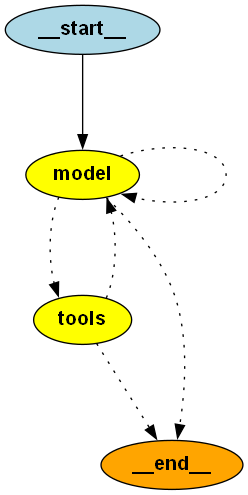

In [34]:
graph = agent.get_graph()
# graph.print_ascii()

display(Image(agent.get_graph().draw_png()))